# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:


# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')



In [3]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users


print(users.isna().sum())
print(users.isna().mean())



user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())
print(usage.isna().mean())



id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- en users las columnas city y churn_date tienen valores faltantes.
   city : 469 con una proporcion del 11.7%
   churn_date :3534 con una proporcion del 88.4%
- en usage date ,duration y lenght tienen valores faltantes
  date:50 con una proporcion del 0.125%
  duration:22076 con una proporcion del 55.2%
  length: 17896 con una proporcion del 44.7%
  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- **acciones recomendadas**
***city***: Investigar si no hay fuente fiable, dejar como nulo (o rellenar con “Desconocido”)-Está en el rango 5–30 %: imputar con la   moda sesgaría la geografía de los usuarios.

***churn_date***:	Ignorar / conservar como nulo- Aquí el nulo tiene significado: el usuario sigue activo, así que no es un dato faltante sino información.

***date***:Eliminar esas filas (o dejar como nulo si no se analiza por fecha) -Es menor al 5 % y sin fecha el registro no se puede ubicar en el tiempo.

***duration***:Investigar, no imputar a ciegas; dejar como nulo- Probablemente solo aplica a un tipo de registro (por ejemplo llamadas), así que revisa la relación con type antes de decidir.

***length***:Investigar, no imputar a ciegas; dejar como nulo-Probablemente solo aplica al otro tipo (por ejemplo mensajes); los nulos serían estructurales, no errores.

  
  

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



- La columna `user_id` Va de 10000 a 13999, con 4 000 valores: es consecutivo y único, sin huecos. La media (11999.5) es exactamente el centro del rango.
  
- La columna `age` Mínimo = -999 Es un valor centinela , no una edad real.
Media (33.7) mucho menor que la mediana (47): el -999 arrastra la media hacia la derecha. Es la señal típica de que hay valores contaminando la columna.
Desviación estándar de 123: absurda para edades. Debería estar alrededor de 15 a 20.
Máximo = 79 y Q1 = 32: sin el centinela, el rango real parece ir de unos 18 a 79 años (esto último es una suposición; el mínimo real no se ve en esta tabla).


In [13]:
usage[['user_id', 'id']].describe()

,user_id,id
count,40000.000000,40000.00000
mean,12002.405975,20000.50000
std,1157.279564,11547.14972
min,10000.000000,1.00000
25%,10996.000000,10000.75000
50%,12013.000000,20000.50000
75%,13005.000000,30000.25000
max,13999.000000,40000.00000


In [14]:
usage[['duration', 'length']].describe()

,duration,length
count,17924.000000,22104.000000
mean,5.202237,52.127398
std,6.842701,56.611183
min,0.000000,0.000000
25%,1.437500,37.000000
50%,3.500000,50.000000
75%,6.990000,64.000000
max,120.000000,1490.000000


- La columna `id`  Va de 1 a 40000 con 40000 valores: es consecutivo y único, sin huecos. La media y la mediana (20000.5) coinciden exactamente con el centro del rango.

- la columna `user_id`Es el mismo resultado que vimos antes (10000 a 13999, sin nulos, distribución casi uniforme). No aparece nada nuevo.

- La columna `duration`Asimétrica a la derecha: la media (5.2) es mayor que la mediana (3.5), y el 75 % de los valores está por debajo de 6.99.
Máximo = 120: es unas 17 veces el percentil 75. Puede ser una llamada larga real o un error, y hay que revisarlo.
Mínimo = 0: posible si son llamadas perdidas o fallidas, pero conviene confirmarlo.

- La columna `length`Más simétrica: media 52 y mediana 50, con cuartiles razonables (37 a 64).
Máximo = 1490: es un outlier extremo frente al percentil 75 (64). Parece un error o un caso excepcional.
Mínimo = 0: mensajes vacíos o registros sin contenido.

In [15]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']


In [16]:
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

In [17]:
users['plan'].value_counts()

Basico     2595
Premium    1405
Name: plan, dtype: int64

- La columna `city` hay 6 ciudades con nombres y una con "?" con 96 filas que nos da la idea que son sentinels
- La columna `plan` tiene dos valores sin ningun problema aparente 

In [18]:

# explorar columna categórica de usage
usage['type'].value_counts()


text    22092
call    17908
Name: type, dtype: int64

- La columna `type` tiene dos valores sin ningun problema aparente 


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- en la columna city se encuentra  "?" con 96 datos registrados 
- ¿Qué acción tomarías?
-  se recomienda Reemplazar por NaN y tratarlo con los 469 nulos (565 en total, 14.1 %)-Es un nulo disfrazado. No imputar con la moda para no sesgar la geografía. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [19]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [20]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])


In [21]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, Años 2022, 2023 y 2024 tienen entre 1314 y 1330 registros cada uno. La distribución es muy pareja, lo que sugiere altas constantes durante tres años. Falta 2025: hay un hueco de un año completo entre 2024 y 2026. Con la tendencia anterior se esperarían unos 1300 registros, y no hay ninguno.

In [22]:

usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`,  los 39950 mas 50 nulos para un total de 40000 registros con fecha son todos de 2024   . No hay años muy viejos ni años futuros, y tampoco fechas con formato inválido.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
-solo hay una ventana temporal , todo el uso es del 2024 
- No hay años imposibles en date, Todo cae en 2024. El problema está en reg_date: los 40 registros de 2026 quedan fuera del rango de los datos de uso.
- recordar que tenemos 50 nulos 
  
- ¿Qué harías con ellas?
- Tomar 2024 como la ventana de análisis --Es la base para las comparaciones con las demás fechas.
- con los  40 registros de 2026 ,Marcar con bandera y excluir del análisis temporal; no corregir a ciegas-- Contradicen la ventana de 2024. Probablemente son un error de captura, pero es una hipótesis sin confirmar.
- con los 50 nulos: Eliminar esas filas o dejar como NaT--Son menos del 5 % y sin fecha no se pueden ubicar en el tiempo.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [23]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)
# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [24]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

print((users['city'] == '?').sum())  
print(users['city'].isna().sum())


0
565


In [25]:

# Marcar fechas futuras como NA para reg_date
limite = usage['date'].max()
users.loc[users['reg_date'] > limite, 'reg_date'] = pd.NaT

print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())
print(users['reg_date'].isna().sum())  


2022.0    1314
2023.0    1316
2024.0     659
NaN        711
Name: reg_date, dtype: int64
711


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [26]:
# Verificación MAR en usage (Missing At Random) para duration

def proporcion_nulos(x):
    return x.isna().mean()

# Verificación MAR para duration
print(usage.groupby('type')['duration'].apply(proporcion_nulos))





type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [27]:
# Verificación MAR en usage (Missing At Random) para length
print(usage.groupby('type')['length'].apply(proporcion_nulos))

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Qué veo: los nulos de duration y length dependen de type.

duration falta en casi el 100 % de los text y en 0 % de los call.
length falta en casi el 100 % de los call y en 0 % de los text.

Conclusión: son MAR, porque la ausencia se explica por otra columna (type). En el fondo, un texto no tiene duración y una llamada no tiene longitud, así que el dato “no aplica”.

Decisión: dejarlos como nulos. Imputarlos inventaría duraciones para textos y longitudes para llamadas, y eliminarlos haría perder más de la mitad de las filas.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [28]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [29]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile =  users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [31]:
# Resumen estadístico de las columnas numéricas
cols_num = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
print(user_profile[cols_num].describe())


               age  cant_mensajes  cant_llamadas  cant_minutos_llamada
count  4000.000000    3999.000000    3999.000000           3999.000000
mean     48.136000       5.524381       4.478120             23.317054
std      17.689919       2.358416       2.144238             18.168095
min      18.000000       0.000000       0.000000              0.000000
25%      33.000000       4.000000       3.000000             11.120000
50%      48.000000       5.000000       4.000000             19.780000
75%      63.000000       7.000000       6.000000             31.415000
max      79.000000      17.000000      15.000000            155.690000


In [32]:
# Distribución porcentual del tipo de plan
print((user_profile["plan"].value_counts(normalize=True) * 100).round(2))

Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

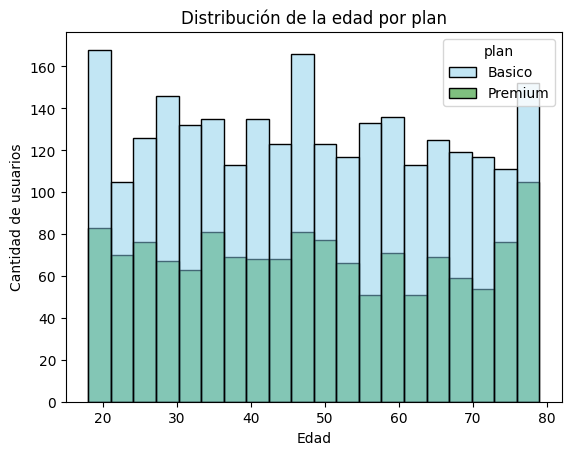

In [33]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x="age", hue="plan", palette=["skyblue", "green"], bins=20)
plt.title("Distribución de la edad por plan")
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución aproximadamente uniforme: las barras son parejas entre 18 y 79 años, sin una campana clara.
Los dos planes se comportan igual: Básico tiene más usuarios en cada rango, pero la forma es la misma. No existe un patrón de edad por plan.
El rango ya es realista (18 a 79), así que el -999 quedó corregido

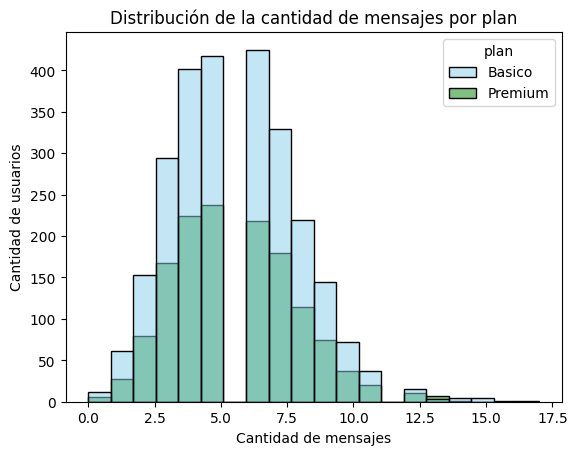

In [34]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x="cant_mensajes", hue="plan", palette=["skyblue", "green"], bins=20)
plt.title("Distribución de la cantidad de mensajes por plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución casi simétrica (campana), con el pico entre 4 y 7 mensajes por usuario y una cola corta a la derecha (12 a 17).
Ambos planes tienen la misma forma y el mismo pico. Básico tiene más usuarios, pero no mandan más mensajes. No se observa un patrón por plan.
Hay pocos usuarios con más de 12 mensajes: son los valores extremos.

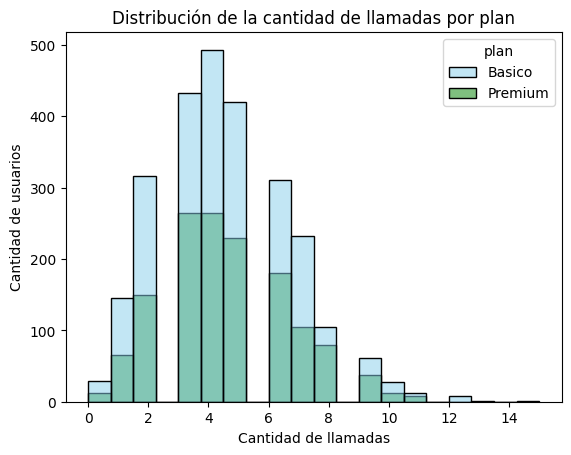

In [35]:

# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x="cant_llamadas", hue="plan", palette=["skyblue", "green"], bins=20)
plt.title("Distribución de la cantidad de llamadas por plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.show()


💡Insights: 
- Distribución ligeramente sesgada a la derecha: el pico está en 3 a 5 llamadas y la cola llega hasta 14 o 15.
Ambos planes tienen el mismo pico y la misma forma. No hay diferencia de comportamiento por plan.
Pocos usuarios superan las 10 llamadas.

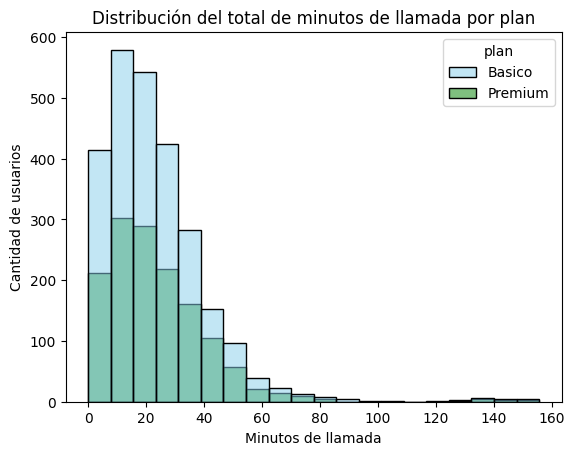

In [36]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x="cant_minutos_llamada", hue="plan", palette=["skyblue", "green"], bins=20)
plt.title("Distribución del total de minutos de llamada por plan")
plt.xlabel("Minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.show()

💡Insights: 
- Distribución claramente sesgada a la derecha: la mayoría de los usuarios está entre 0 y 40 minutos, con el pico cerca de 10 a 20, y hay una cola larga hasta unos 155.
Los dos planes tienen la misma forma. Hay un pequeño grupo de usuarios entre 120 y 155 minutos, aislado del resto: son outliers y conviene revisarlos en el paso siguiente (boxplot).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

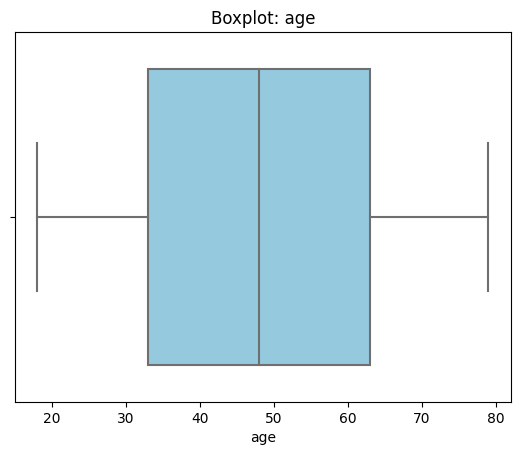

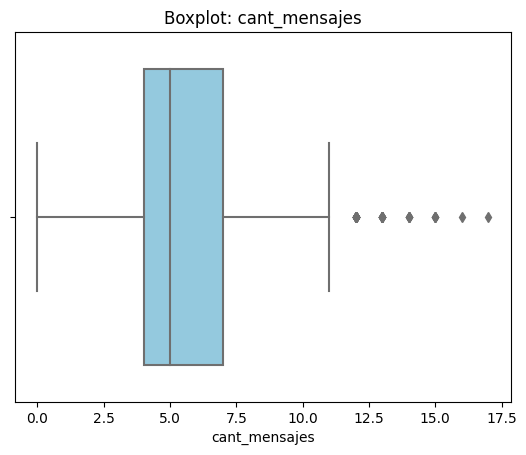

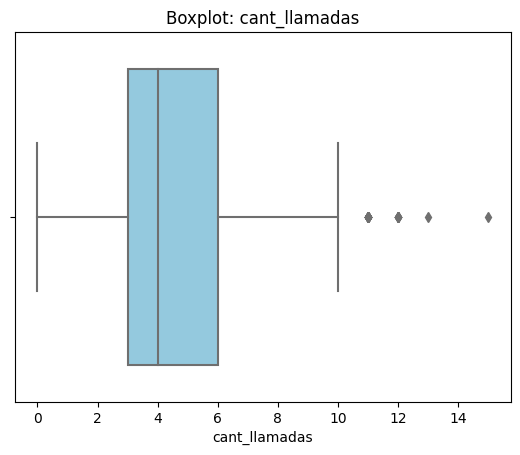

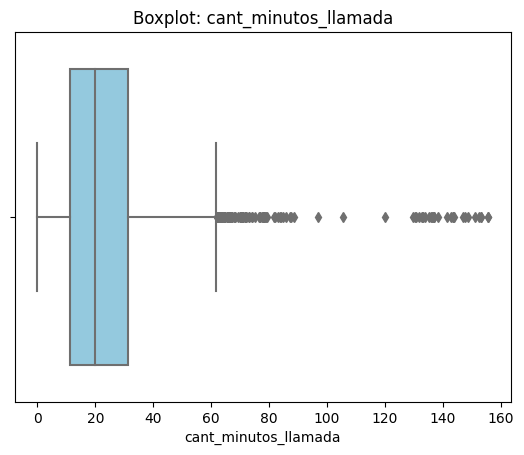

In [37]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()



💡Insights: 
- Age: no presenta outliers. Los bigotes llegan hasta 18 y 79 sin puntos sueltos, y la mediana (cerca de 48) queda en el centro de la caja. Distribución simétrica y rango realista.
  
- cant_mensajes: sí presenta outliers, solo del lado superior. Aparecen puntos desde 12 hasta 17 mensajes, fuera del bigote derecho (que llega a 11). Son pocos y valores plausibles, no errores.
 
- cant_llamadas: sí presenta outliers, solo del lado superior. Hay puntos en 11, 12, 13 y 15 llamadas, fuera del bigote (que llega a 10). Son pocos y leves.
  
- cant_minutos_llamada:sí presenta outliers, solo del lado superior, y son los más marcados. Hay muchos puntos desde unos 62 minutos en adelante, y un grupo aislado entre 130 y 155, lejos del resto. Es la única variable con una cola larga.


In [38]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    print(col)
    print('  Q1:', q1)
    print('  Q3:', q3)
    print('  IQR:', iqr)
    print('  Límite superior:', limite_superior)
    print('  Máximo:', user_profile[col].max())
    print('  Outliers:', (user_profile[col] > limite_superior).sum())
    print()



cant_mensajes
  Q1: 4.0
  Q3: 7.0
  IQR: 3.0
  Límite superior: 11.5
  Máximo: 17.0
  Outliers: 46

cant_llamadas
  Q1: 3.0
  Q3: 6.0
  IQR: 3.0
  Límite superior: 10.5
  Máximo: 15.0
  Outliers: 30

cant_minutos_llamada
  Q1: 11.12
  Q3: 31.415
  IQR: 20.295
  Límite superior: 61.8575
  Máximo: 155.69
  Outliers: 109



In [39]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué:
mantener. El máximo (17) está apenas 5.5 por encima del límite (11.5) y es un valor posible: 17 mensajes en el año es poco. Es un outlier leve, no un error.
  
- cant_llamadas: mantener o no outliers, porqué?:
mantener. El máximo (15) está 4.5 por encima del límite (10.5). También es leve y plausible. Eliminarlo no mejora el análisis y pierde usuarios reales.

- cant_minutos_llamada: mantener o no outliers, porqué?:
mantener. El máximo (155.69) está muy por encima del límite (61.86), pero es un valor posible: corresponde a usuarios muy activos, no a un error de captura. La media (23.3) queda por encima de la mediana (19.8) por estos casos, así que para describir el uso típico conviene la mediana.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso
def clasificar_uso(fila):
    if fila['cant_llamadas'] < 5 and fila['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif fila['cant_llamadas'] < 10 and fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [41]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:

# Crear columna grupo_edad
def clasificar_edad(edad):
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)


In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

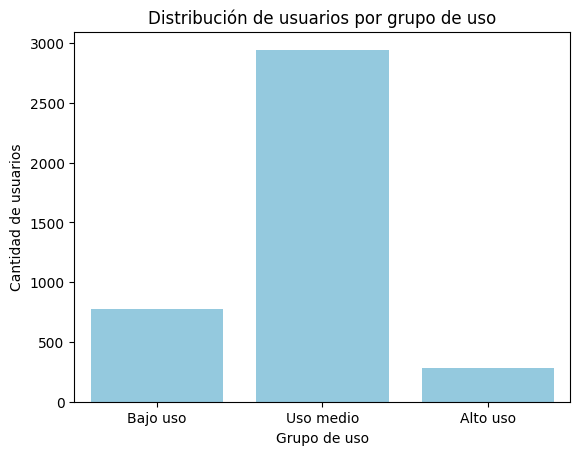

In [48]:

# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()




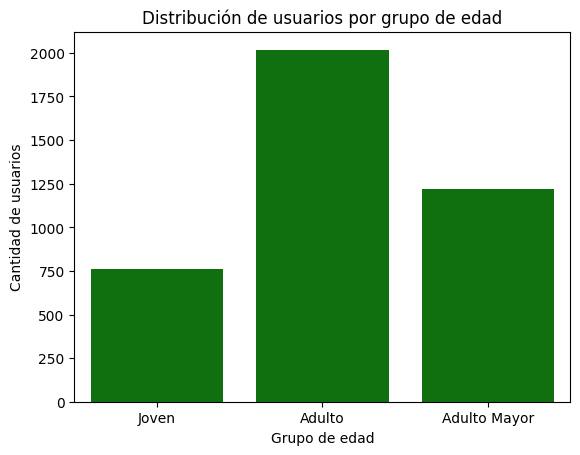

In [47]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='green')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

***age:*** 55 filas (1.4 %) tenían el centinela -999, un nulo disfrazado que isna() no detectaba. Se reemplazaron por la mediana.

***city:*** 565 filas (14.1 %) sin dato: 469 nulos y 96 con "?". Se convirtieron a nulo y no se imputaron, para no sesgar la geografía.

***reg_date:*** 711 registros (17.8 %) se marcaron como nulos por ser posteriores al 30 de junio de 2024, fin de la ventana de uso: 40 de 2026 y 671 de la segunda mitad de 2024. No hay altas en 2025.

***date (uso):*** 50 nulos (0.125 %).

***duration y length:*** 55.2 % y 44.7 % de nulos. Dependen de type (un texto no tiene duración ni una llamada tiene longitud), así que se dejaron como nulos.
28 filas (0.07 %) tenían la medida del tipo equivocado. El impacto es mínimo.
1 usuario sin registros de uso, que no se corrigió por su impacto mínimo (ver Limitaciones).
churn_date: 88.4 % de nulos, que corresponde a usuarios activos. La tasa de cancelación global es de 11.65 %.

🔍 **Segmentos por edad**
Adulto (30 a 59 años): 2 018 usuarios (50.4 %).
Adulto Mayor (60 o más): 1 222 usuarios (30.6 %).
Joven (menos de 30): 760 usuarios (19.0 %).
La edad es casi uniforme entre 18 y 79, así que el tamaño de cada grupo refleja el ancho de su rango.
No hay diferencias de edad entre Básico y Premium.

📊 **Segmentos por nivel de uso**
Uso medio: 2 943 usuarios (73.6 %).
Bajo uso: 778 usuarios (19.4 %).
Alto uso: 279 usuarios (7.0 %).
Las medianas son 5 mensajes, 4 llamadas y 19.8 minutos: el usuario típico usa el servicio de forma moderada.
Básico y Premium se comportan casi igual. Alto uso es 7.2 % en Básico (186 usuarios) y 6.6 % en Premium (93). Bajo uso es 19.7 % y 18.9 %, y Uso medio 73.1 % y 74.4 %.
Cancelación por grupo: Alto uso 14.0 %, Uso medio 11.5 % y Bajo uso 11.4 %. Bajo uso no cancela más que el promedio.

➡️ Esto sugiere que Premium no se diferencia por comportamiento: sus usuarios consumen igual que los de Básico, así que el plan no refleja cuánto usa cada cliente. El segmento de mayor consumo (Alto uso) es también el que más cancela, aunque la diferencia es pequeña y la muestra reducida (unos 39 casos).

🏆 **Segmentos más valiosos**
Alto uso (279 usuarios, 7 %): consumen más y podrían generar más ingreso si el plan lo captura. Perderlos es costoso porque tienen la mayor cancelación.
Uso medio (73.6 %): es la base del negocio por volumen.
Adultos de 30 a 59 años: son la mitad de los clientes.
Esta valoración es una inferencia por volumen y consumo. No hay datos de ingresos, así que no se puede confirmar el valor monetario de cada segmento.

🔥 **Outliers**
Solo hay valores extremos del lado superior: mensajes sobre 11.5 (máx. 17), llamadas sobre 10.5 (máx. 15) y minutos sobre 61.86 (máx. 155.69). age no tiene outliers.
Se mantuvieron: son valores posibles de usuarios muy activos, no errores de captura.
Son los clientes de mayor consumo: potencialmente los más valiosos, pero también los más costosos de atender si el plan no cobra por exceso.
Los minutos inflan la media (23.3) frente a la mediana (19.8), por lo que conviene reportar la mediana.

💡 **Recomendaciones**
Rediseñar Premium para que justifique su precio, con beneficios que valore un usuario activo (más minutos o mensajes, soporte prioritario).
Upgrade dirigido a los 186 usuarios de Alto uso en Básico (7.2 % de ese plan).
Programa de retención para Alto uso (14.0 % de cancelación). Conviene confirmar la diferencia con más datos antes de invertir mucho.
Plan económico para Bajo uso (778 usuarios, 19.4 %). El argumento es de eficiencia de precio, ya que no hay evidencia de que cancelen más.
Cobro escalonado por minutos extra para llamadas de más de 62 minutos.
Calidad de datos: exigir city y age en el registro, y no usar -999 ni "?" como código de “desconocido”.




---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`